# 33회 후기 유형 연습 해설

공식 원문·정답이 아닌 창작 합성 자료입니다. README와 출처·보완 명세를 먼저 확인하세요. Python 3.12 별도 실행 환경을 사용합니다. 아래 문제 지문은 PDF와 같으며 설명 셀의 선택 근거·가정·가설과 실행 출력의 계산값·기각 여부·상황 결론을 함께 읽으세요. `분석코드.py`로 같은 계산을 일괄 실행할 수 있습니다.

In [1]:
from pathlib import Path
import sys
FOLDER = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
repo = next(p for p in [FOLDER]+list(FOLDER.parents) if (p/'tools/exams').is_dir())
sys.path.insert(0,str(repo/'기출문제/유형연습/공통'))
from analysis import Context
ctx=Context(FOLDER)


## 1. 질환 단계 예측

hepatitis.csv의 Category는 0=정상, 1~3=질환 단계이며 x1~x6는 수치형 검사다. id mod 5=0이 보류 구간이다. 1번 전체는 같은 자료를 사용하며 리샘플링은 학습 폴드에서만 수행한다.

### 1-1

**문제** 결측 처리 대안 두 가지를 비교하고 품질·분포·공선성을 조사하시오. 타깃을 이용하지 않는 주성분 표현의 필요성과 해석 손실을 설명하시오.

**풀이·선택 근거·해석**

중앙값 대치와 행 삭제를 비교하되 삭제의 표본 손실을 기록한다. PCA는 입력 특성으로만 적합하며 타깃 번호를 연속 특성처럼 넣지 않는다.

In [2]:
ctx.run('1-1', 'hepatitis_prepare')


=== 1-1 ===
missing/deletion loss
{
  "missing": {
    "x1": 0,
    "x2": 13,
    "x3": 0,
    "x4": 0,
    "x5": 0,
    "x6": 0
  },
  "deleted_rows": 13
}
PCA training variance
[
  0.2059740256544732,
  0.19144880035683284,
  0.1669627909563477,
  0.15929723138407417,
  0.14589806786964313,
  0.13041908377862896
]


### 1-2

**문제** 정상 대 질환의 이진 타깃을 만들고 원 학습과 무작위 오버/언더 표본 대안을 비교하시오. CV의 F1과 원 분포 보류 평가에서 precision·recall·F1·AUC를 보고하시오.

**풀이·선택 근거·해석**

인위적으로 균형을 맞춘 평가 자료를 사용하지 않는다. 두 보완은 폴드 안에서만 수행하며 사전 threshold=.5로 평가한다.

In [3]:
ctx.run('1-2', 'hepatitis_binary')


=== 1-2 ===
sampling CV F1
{
  "scores": {
    "None": 0.695116662329777,
    "over": 0.7025089605734767,
    "under": 0.705026455026455
  },
  "chosen": "under"
}
holdout
{
  "precision": 0.7407407407407407,
  "recall": 0.8333333333333334,
  "F1": 0.7843137254901961,
  "AUC": 0.8715277777777778
}


### 1-3

**문제** 질환군 1~3만 남겨 서로 다른 세 분류 모형을 같은 macro-F1 기준으로 비교하시오. 선택 모형의 보류 혼동행렬·정밀도·재현율과 특성 중요도 해석을 제시하시오.

**풀이·선택 근거·해석**

이진 문제와 다중 문제의 모집단을 구분한다. 세 후보 Logistic·RF·GradientBoosting의 학습 CV로 선택한다. 중요도와 상관·인과 효과는 다르다.

In [4]:
ctx.run('1-3', 'hepatitis_multi')


=== 1-3 ===
CV selection
{
  "scores": {
    "Logistic": 0.3996610556448285,
    "RF": 0.377962579369229,
    "GB": 0.36114561766735687
  },
  "chosen": "Logistic",
  "metric": "f1_macro",
  "selection": "training CV only"
}
holdout
{
  "F1": 0.30687830687830686,
  "confusion_matrix": [
    [
      4,
      1,
      1
    ],
    [
      5,
      5,
      2
    ],
    [
      3,
      3,
      0
    ]
  ],
  "classification_report": {
    "1": {
      "precision": 0.3333333333333333,
      "recall": 0.6666666666666666,
      "f1-score": 0.4444444444444444,
      "support": 6.0
    },
    "2": {
      "precision": 0.5555555555555556,
      "recall": 0.4166666666666667,
      "f1-score": 0.47619047619047616,
      "support": 12.0
    },
    "3": {
      "precision": 0.0,
      "recall": 0.0,
      "f1-score": 0.0,
      "support": 6.0
    },
    "accuracy": 0.375,
    "macro avg": {
      "precision": 0.2962962962962963,
      "recall": 0.3611111111111111,
      "f1-score": 0.30687830687

## 2. 지하철 이용량과 날씨

subway.csv는 date·board·h05·h06·h07의 wide 표다. on/off를 합쳐 일별 이용량을 구성한다. weather.csv에는 일부 날짜 행 자체가 없다. 결측 강수값 0 대치는 원래 존재하는 날의 측정 결측에만 적용한다. 날짜가 누락된 날은 별도 플래그·학습 중앙값으로 처리한다. 2021~2022는 학습, 2023은 최종 시험이다.

### 2-1

**문제** 이용량 표를 변환·집계하고 날씨를 날짜로 일대일 결합하시오. 중복 키·미매칭 행을 검사하고 주말 여부를 생성하시오. 숫자 결측과 날짜 누락의 차이를 설명하시오.

**풀이·선택 근거·해석**

그리드와 관측 키를 대조하고 집계 후 validate=one_to_one으로 결합한다. 누락된 날짜를 관측 강수 0과 동일시하지 않는다.

In [5]:
ctx.run('2-1', 'subway_merge')


=== 2-1 ===
merge validation
{
  "rows": 79,
  "input_days": 79,
  "unmatched": 2,
  "description": [
    {
      "index": "count",
      "date": 79,
      "users": 79.0,
      "temp": 77.0,
      "rain": 77.0,
      "weather_missing": 79.0,
      "weekend": 79.0,
      "season": 79.0
    },
    {
      "index": "mean",
      "date": "2022-07-01 00:00:00",
      "users": 351.7360062379746,
      "temp": 14.991008944285715,
      "rain": 2.4413182785623375,
      "weather_missing": 0.02531645569620253,
      "weekend": 0.0,
      "season": 2.5569620253164556
    },
    {
      "index": "min",
      "date": "2021-01-01 00:00:00",
      "users": 191.60698059999999,
      "temp": 3.08749351,
      "rain": 0.0,
      "weather_missing": 0.0,
      "weekend": 0.0,
      "season": 1.0
    },
    {
      "index": "25%",
      "date": "2021-10-01 00:00:00",
      "users": 316.9728917,
      "temp": 7.0425281,
      "rain": 0.436968421,
      "weather_missing": 0.0,
      "weekend": 0.0,
      "

### 2-2

**문제** 날씨·주말 특성으로 이용량을 예측하는 선형 및 트리 모형을 시간순 CV로 비교하시오. 정해진 최종 연도의 RMSE·MAE·R²와 시간 의존성에 따른 한계를 보고하시오.

**풀이·선택 근거·해석**

전처리와 선택은 과거 폴드에만 적합한다. 무작위 CV를 시간 자료에 적용하지 않는다. 시험 연도는 최종 평가에만 사용한다.

In [6]:
ctx.run('2-2', 'subway_models')


=== 2-2 ===
CV selection
{
  "scores": {
    "Linear": 31.20166321043998,
    "RF": 45.98845539676619,
    "GB": 47.263096931024926
  },
  "chosen": "Linear",
  "metric": "RMSE",
  "selection": "training CV only"
}
holdout
{
  "RMSE": 14.259838445398108,
  "MAE": 11.584163442100508,
  "R2": 0.8919514542067878,
  "n": 26
}
split IDs
{
  "train_index": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    44,
    45,
    46,
    47,
    48,
    49,
    50,
    51,
    52
  ],
  "test_index": [
    53,
    54,
    55,
    56,
    57,
    58,
    59,
    60,
    61,
    62,
    63,
    64,
    65,
    66,
    67,
    68,
    69,
    70,
    71,
    72,
    73,
    74,
    75,
    76,
    77,
    78
 

## 3. 공정·연착·시간 의존성

defect.csv는 독립 추출한 A/B 공정의 불량률(연속 %)이며 paired가 아니다. counts.csv는 같은 노선에서 독립인 동일 시간창별 연착 건수다. delay.csv는 독립 사건의 line·minutes다. series.csv는 단일 시계열이다. 서로 별도 자료다.

### 3-1

**문제** 두 공정의 평균 불량률 차이를 평가하시오. 평균·표준편차·차이, 적절한 검정·가설·통계량·p-value·기각 여부를 제시하시오. 일별 비율과 이항 성공/실패 원시 건수의 차이를 설명하시오.

**풀이·선택 근거·해석**

독립 연속 비율의 평균 비교에는 Welch t를 사용한다. 분모가 없는 비율에 두 비율 z검정을 적용하지 않는다. 정규 모집단을 작업 가정으로 둔다.

In [7]:
ctx.run('3-1', 'defect')


=== 3-1 ===
summary
{
  "A": {
    "count": 100.0,
    "mean": 3.8383391263999997,
    "std": 0.8364191632915294,
    "min": 1.87170951,
    "25%": 3.2963572125000002,
    "50%": 3.78396379,
    "75%": 4.338054895,
    "max": 6.25369013
  },
  "B": {
    "count": 100.0,
    "mean": 4.3399039324,
    "std": 1.252607254923184,
    "min": 1.63068706,
    "25%": 3.55444582,
    "50%": 4.30561327,
    "75%": 4.99322057,
    "max": 8.07176468
  },
  "difference": -0.5015648060000006
}
{
  "method": "Welch t",
  "H0": "mu_A=mu_B",
  "H1": "mu_A != mu_B",
  "statistic": -3.3300134687718006,
  "p_value": 0.0010618465228373754,
  "df": null,
  "alpha": 0.05,
  "reject_H0": true,
  "conclusion": "유의수준 5%에서 평균 불량률 차이에 대한 근거가 있다."
}


### 3-2

**문제** 연착 건수 자료가 하나의 일정률 발생 모형에 맞는지 평가하시오. 모수를 추정하고 관측·기대 빈도를 만들며 기대도수가 5 이상이 되도록 꼬리를 합치시오. 모수 추정 자유도·p-value·판정을 보고하시오.

**풀이·선택 근거·해석**

Poisson 평균을 표본으로 추정하므로 df=합친 범주수-1-1이다. 임의 bin 경계를 사후 고르지 않고 왼쪽부터 누적 기대빈도5가 되면 묶는 규칙을 고정한다.

In [8]:
ctx.run('3-2', 'poisson_gof')


=== 3-2 ===
pooled bins
{
  "lambda_est": 3.1925,
  "bins": [
    [
      0,
      0,
      13,
      16.427627926666126
    ],
    [
      1,
      1,
      60,
      52.44520215588161
    ],
    [
      2,
      2,
      80,
      83.715653941326
    ],
    [
      3,
      3,
      92,
      89.08740840256108
    ],
    [
      4,
      4,
      61,
      71.10288783129405
    ],
    [
      5,
      5,
      49,
      45.39919388028128
    ],
    [
      6,
      6,
      32,
      24.15615441046631
    ],
    [
      7,
      7,
      7,
      11.016931850773377
    ],
    [
      8,
      19,
      6,
      6.6489396007500785
    ]
  ],
  "n": 400,
  "df": 7
}
{
  "method": "Estimated-Poisson Pearson GOF",
  "H0": "counts follow Poisson(lambda)",
  "H1": "not Poisson",
  "statistic": 7.859666390446052,
  "p_value": 0.3451310065166741,
  "df": 7,
  "alpha": 0.05,
  "reject_H0": false,
  "conclusion": "유의수준 5%에서 포아송 분포 부적합에 대한 근거가 충분하지 않다."
}


### 3-3

**문제** 노선과 연착 구간(≤10, 10초과~20, >20분)의 관련성을 평가하시오. 구간 경계·관측/기대도수·가설·통계량·자유도·p-value·기각 여부를 제시하시오.

**풀이·선택 근거·해석**

사건 하나는 한 셀에만 포함한다. 전체 카이제곱 검정의 독립성 가정과 기대도수를 점검한다.

In [9]:
ctx.run('3-3', 'delay')


=== 3-3 ===
line_table
[
  {
    "line": "L1",
    "le10": 40,
    "10to20": 8,
    "gt20": 6
  },
  {
    "line": "L2",
    "le10": 38,
    "10to20": 13,
    "gt20": 6
  },
  {
    "line": "L3",
    "le10": 36,
    "10to20": 16,
    "gt20": 10
  },
  {
    "line": "L4",
    "le10": 37,
    "10to20": 12,
    "gt20": 18
  }
]
line_expected
[
  [
    33.975,
    11.025,
    9.0
  ],
  [
    35.8625,
    11.6375,
    9.5
  ],
  [
    39.00833333333333,
    12.658333333333333,
    10.333333333333334
  ],
  [
    42.15416666666667,
    13.679166666666667,
    11.166666666666666
  ]
]
{
  "method": "Pearson independence line-interval",
  "H0": "line independent of interval",
  "H1": "line associated with interval",
  "statistic": 10.617667256882592,
  "p_value": 0.10093637998910636,
  "df": 6,
  "alpha": 0.05,
  "reject_H0": false,
  "conclusion": "유의수준 5%에서 line와 interval의 관련성에 대한 근거가 충분하지 않다."
}


### 3-4

**문제** ACF·PACF를 설명하고 자료의 정상성을 진단하시오. ARMA 후보 (1,0),(2,0),(1,1),(2,1)을 학습 80%에서 AIC로 고르고, 시험 20%의 RMSE 및 선택 모형 잔차 10시차 진단을 제시하시오.

**풀이·선택 근거·해석**

ADF H0는 단위근 존재다. ARIMA(p,0,q) 후보는 같은 학습 구간·상수로 비교한다. Ljung-Box의 model_df=p+q를 차감한다. 비기각은 백색잡음의 증명이 아니다.


=== 3-4 ===
{
  "method": "ADF",
  "H0": "unit root",
  "H1": "stationary",
  "statistic": -6.937764362846642,
  "p_value": 1.0439248306821263e-09,
  "df": null,
  "alpha": 0.05,
  "reject_H0": true,
  "conclusion": "유의수준 5%에서 단위근 가설의 기각에 대한 근거가 있다."
}
ARMA candidates/forecast
{
  "candidates": [
    {
      "p": 1,
      "q": 0,
      "AIC": 522.5529866520504,
      "converged": true
    },
    {
      "p": 2,
      "q": 0,
      "AIC": 510.62280058427814,
      "converged": true
    },
    {
      "p": 1,
      "q": 1,
      "AIC": 511.12308509806815,
      "converged": true
    },
    {
      "p": 2,
      "q": 1,
      "AIC": 512.3582730518802,
      "converged": true
    }
  ],
  "selected": {
    "p": 2,
    "q": 0,
    "AIC": 510.62280058427814,
    "converged": true
  },
  "holdout_RMSE": 1.162271798816227
}
{
  "method": "Ljung-Box lag10",
  "H0": "no residual autocorrelation through lag10",
  "H1": "some residual autocorrelation",
  "statistic": 4.796497107736262,
  "p_value

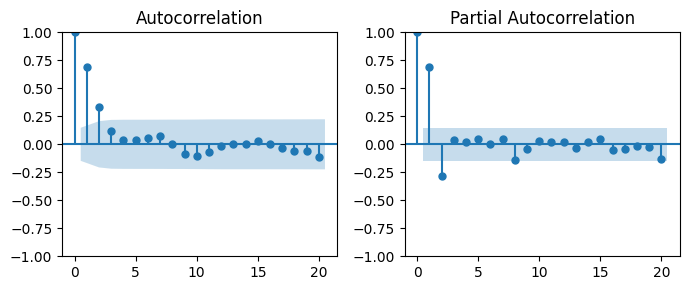

In [10]:
ctx.run('3-4', 'arma')